<a href="https://colab.research.google.com/github/raghaveni-p/aas/blob/main/Another_copy_of_ml_casestudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Mushroom Edibility Classification Using Machine Learning**



# INDEX

| Sl. No. | Contents |
|---|---|
| 1. | Introduction |
| 2. | Importing Required Libraries |
| 3. | Loading the Dataset |
| 4. | Data Exploration |
| 5. | Data Preprocessing |
| 6. | Data Analytics and Visualization |
| 7. | Splitting the Dataset into Training and Testing Sets |
| 8. | Model Building and Training |
| 8.1 | Decision Tree Classifier |
| 8.2 | Naive Bayes Classifier |
| 8.3 | K-Nearest Neighbors (KNN) Classifier |
| 9. | Model Evaluation |
| 9.1 | Classification Report |
| 9.2 | Confusion Matrix |
| 10. | Decision Tree Visualization |
| 11. | Decision Tree Rules |
| 12. | Feature Importance Analysis |
| 13. | Model Comparison |
| 14. | Conclusion |

## **Introduction**

Mushroom classification is an important application of Machine Learning that helps identify whether a mushroom is edible or poisonous based on its physical characteristics.

In this project, the Mushroom Dataset is used to develop machine learning models that classify mushrooms into two categories: edible and poisonous. The dataset contains different features such as cap shape, cap color, odor, gill size, stalk shape, population, and habitat.

Three machine learning algorithms are implemented:
1. Decision Tree Classifier
2. Naive Bayes Classifier
3. K-Nearest Neighbors (KNN) Classifier

The performance of these models is evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The results are compared to understand which algorithm performs better on the given dataset.

The main objective of this project is to understand how machine learning techniques can be used for classification problems.

## 1. Project Objective

The main objective of this project is to develop a Machine Learning model that can classify mushrooms into two categories: edible and poisonous based on their physical characteristics.

The specific objectives are:

- To explore and understand the Mushroom Dataset.
- To perform data preprocessing and prepare the dataset for machine learning.
- To analyze different mushroom features using data visualization.
- To implement Decision Tree, Naive Bayes, and K-Nearest Neighbors (KNN) algorithms.
- To evaluate the performance of the models using accuracy, precision, recall, F1-score, and confusion matrix.
- To compare the performance of the three algorithms and identify the best-performing model.

## 2. Dataset Description

The Mushroom Classification project uses the Mushroom Dataset from the UCI Machine Learning Repository.

The dataset contains information about different types of mushrooms and their physical characteristics.

**Dataset Details:**

- **Total Records:** 8,124
- **Total Columns:** 23
- **Input Features:** 22
- **Target Variable:** Class
- **Classification Type:** Binary Classification

**Target Classes:**

- `e` – Edible mushrooms
- `p` – Poisonous mushrooms

**Important Features:**

The dataset contains features such as:

- Cap Shape
- Cap Surface
- Cap Color
- Odor
- Gill Size
- Gill Color
- Stalk Shape
- Stalk Root
- Ring Type
- Spore Print Color
- Population
- Habitat

These features are used by machine learning algorithms to identify patterns and classify mushrooms into edible or poisonous categories.

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree, export_text

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [ ]:
# Step 2: Load the dataset

columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color',
    'bruises', 'odor', 'gill-attachment', 'gill-spacing',
    'gill-size', 'gill-color', 'stalk-shape', 'stalk-root',
    'stalk-surface-above-ring', 'stalk-surface-below-ring',
    'stalk-color-above-ring', 'stalk-color-below-ring',
    'veil-type', 'veil-color', 'ring-number', 'ring-type',
    'spore-print-color', 'population', 'habitat'
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

df = pd.read_csv(url, names=columns)

In [ ]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
df.tail()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l
8123,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,o,c,l


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 8124
Number of Columns: 23


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [ ]:
df.describe(include='all')

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


In [ ]:
print(df['class'].value_counts())

class
e    4208
p    3916
Name: count, dtype: int64


In [ ]:
# Step 3: Data preprocessing

# Separate features and target
X = df.drop('class', axis=1)
y = df['class']

# Convert categorical data into numerical data
X = pd.get_dummies(X, dtype=int)

# Display processed data
print(X.head())

# Display target values
print(y.head())

# Check new dataset shape
print("Processed Dataset Shape:", X.shape)

   cap-shape_b  cap-shape_c  cap-shape_f  cap-shape_k  cap-shape_s  \
0            0            0            0            0            0   
1            0            0            0            0            0   
2            1            0            0            0            0   
3            0            0            0            0            0   
4            0            0            0            0            0   

   cap-shape_x  cap-surface_f  cap-surface_g  cap-surface_s  cap-surface_y  \
0            1              0              0              1              0   
1            1              0              0              1              0   
2            0              0              0              1              0   
3            1              0              0              0              1   
4            1              0              0              1              0   

   ...  population_s  population_v  population_y  habitat_d  habitat_g  \
0  ...             1             0  

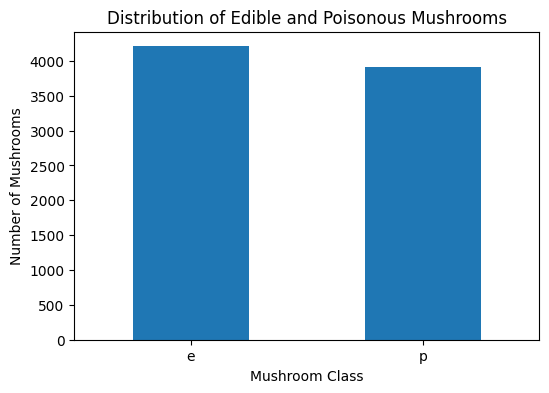

In [ ]:
## 4. Data Analytics and Visualization
plt.figure(figsize=(6, 4))

df['class'].value_counts().plot(kind='bar')

plt.title("Distribution of Edible and Poisonous Mushrooms")
plt.xlabel("Mushroom Class")
plt.ylabel("Number of Mushrooms")
plt.xticks(rotation=0)
plt.show()

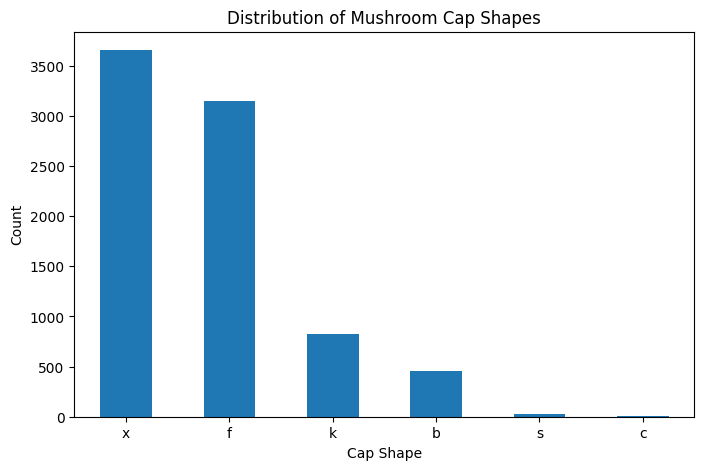

In [ ]:
#Mushroom Class Distribution
plt.figure(figsize=(8, 5))

df['cap-shape'].value_counts().plot(kind='bar')

plt.title("Distribution of Mushroom Cap Shapes")
plt.xlabel("Cap Shape")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

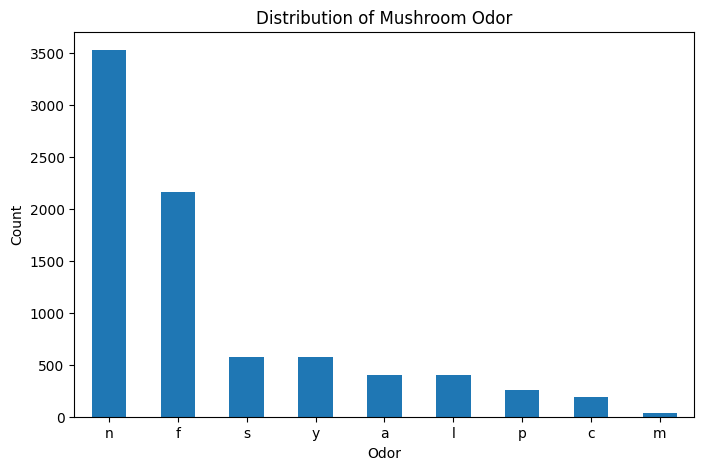

In [ ]:
#Feature Distribution Analysis
plt.figure(figsize=(8, 5))

df['odor'].value_counts().plot(kind='bar')

plt.title("Distribution of Mushroom Odor")
plt.xlabel("Odor")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

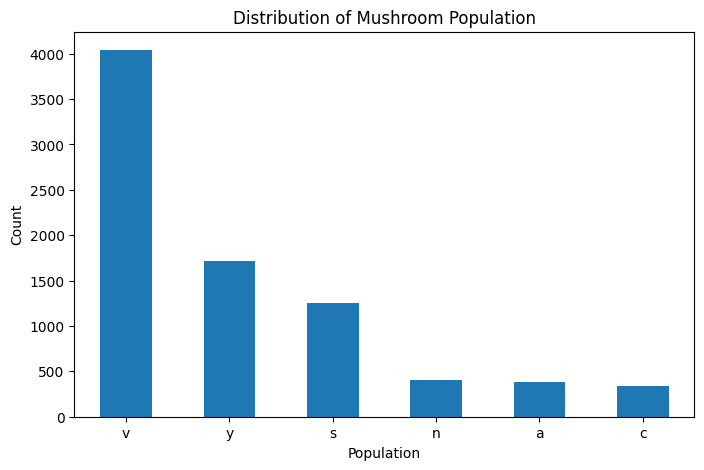

In [ ]:
plt.figure(figsize=(8, 5))

df['population'].value_counts().plot(kind='bar')

plt.title("Distribution of Mushroom Population")
plt.xlabel("Population")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

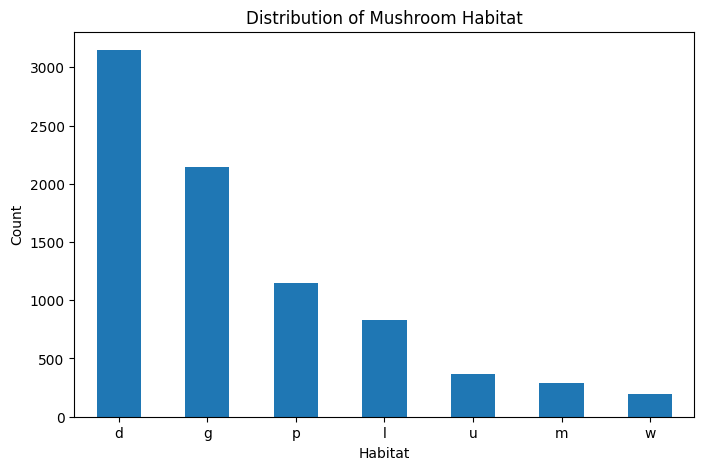

In [ ]:
plt.figure(figsize=(8, 5))

df['habitat'].value_counts().plot(kind='bar')

plt.title("Distribution of Mushroom Habitat")
plt.xlabel("Habitat")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

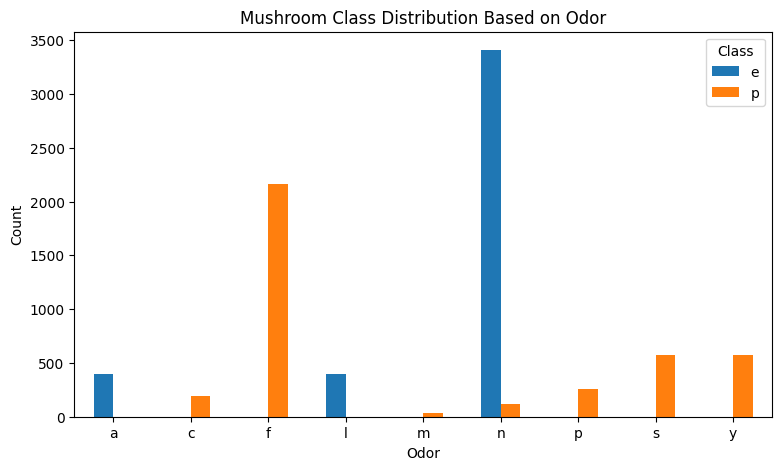

In [ ]:
#Feature-wise Class Analysis
pd.crosstab(df['odor'], df['class']).plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Mushroom Class Distribution Based on Odor")
plt.xlabel("Odor")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

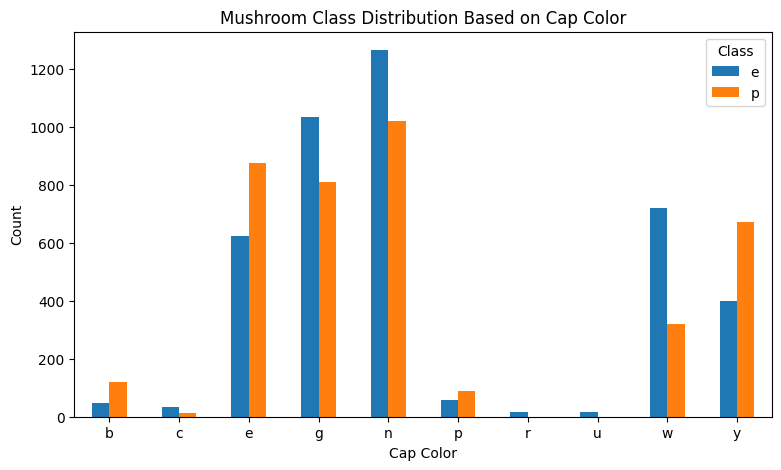

In [ ]:
pd.crosstab(df['cap-color'], df['class']).plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Mushroom Class Distribution Based on Cap Color")
plt.xlabel("Cap Color")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

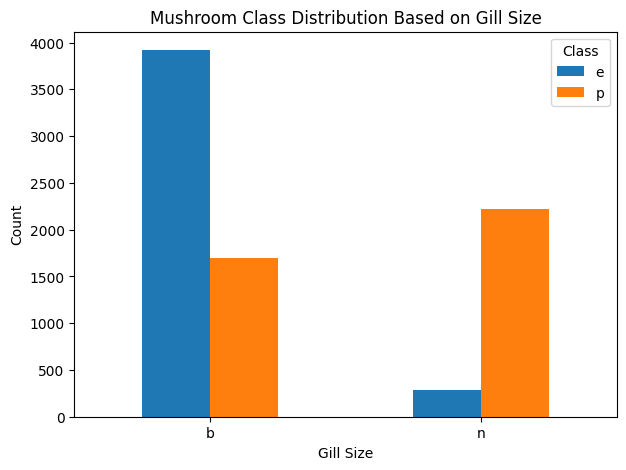

In [ ]:
pd.crosstab(df['gill-size'], df['class']).plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title("Mushroom Class Distribution Based on Gill Size")
plt.xlabel("Gill Size")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

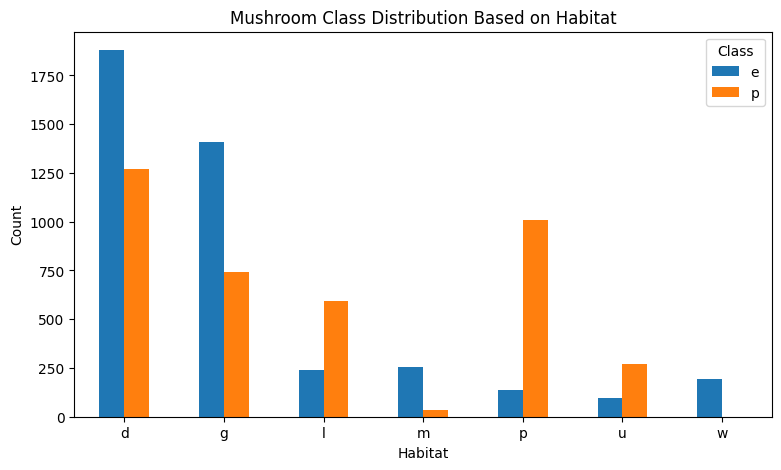

In [ ]:
pd.crosstab(df['habitat'], df['class']).plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Mushroom Class Distribution Based on Habitat")
plt.xlabel("Habitat")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

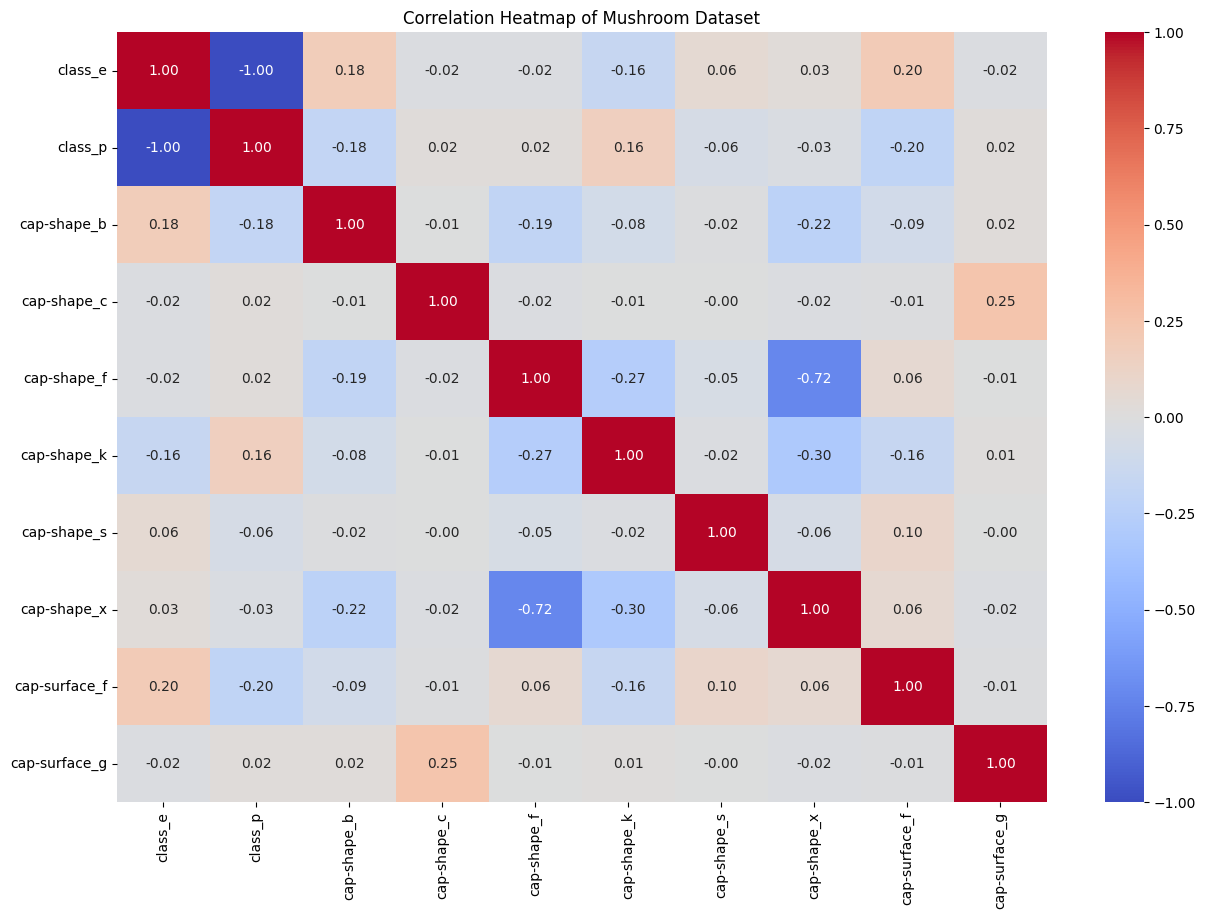

In [ ]:
#Correlation Analysis
plt.figure(figsize=(15, 10))

df_encoded = pd.get_dummies(df, dtype=int)

correlation = df_encoded.corr()

sns.heatmap(
    correlation.iloc[:10, :10],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Mushroom Dataset")
plt.show()

In [ ]:
# Step 4: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6499, 117)
Testing data: (1625, 117)


## 3. Machine Learning Algorithms Used

### 3.1 Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm used for classification and prediction. It works like a flowchart, where each internal node represents a feature, each branch represents a decision, and each leaf node represents the final prediction.

In this project, the Decision Tree algorithm classifies mushrooms as edible or poisonous based on their characteristics.

### 3.2 Naive Bayes Classifier

Naive Bayes is a supervised machine learning algorithm based on Bayes' Theorem. It calculates the probability of a particular class based on the given input features.

In this project, Naive Bayes predicts whether a mushroom is edible or poisonous using its physical features.

### 3.3 K-Nearest Neighbors (KNN) Classifier

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm that classifies data based on the nearest data points.

It finds the K closest neighbors of a given data point and assigns the class that occurs most frequently among those neighbors.

In this project, KNN is used to classify mushrooms based on similarities in their features.

In [ ]:
# Step 5: Decision Tree Classifier

# Create model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100)

# Classification report
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 100.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       843
           p       1.00      1.00      1.00       782

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [ ]:
# Step 6: Naive Bayes Classifier

# Create model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", accuracy_nb * 100)

# Classification report
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 96.0
              precision    recall  f1-score   support

           e       1.00      0.92      0.96       843
           p       0.92      1.00      0.96       782

    accuracy                           0.96      1625
   macro avg       0.96      0.96      0.96      1625
weighted avg       0.96      0.96      0.96      1625



In [ ]:
# Step 7: KNN Classifier

# Create model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train model
knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)

# Calculate accuracy
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn * 100)

# Classification report
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 100.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       843
           p       1.00      1.00      1.00       782

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



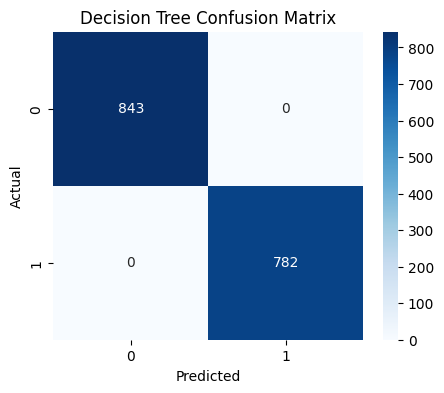

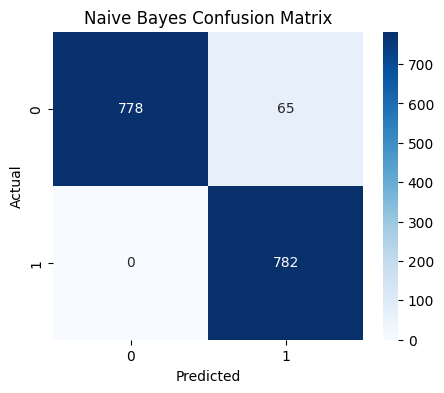

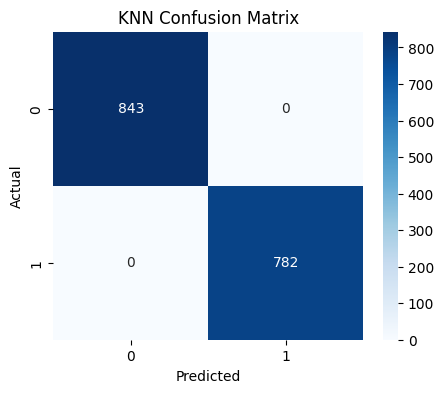

In [ ]:
# Confusion Matrix for all three models

models = {
    'Decision Tree': y_pred_dt,
    'Naive Bayes': y_pred_nb,
    'KNN': y_pred_knn
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

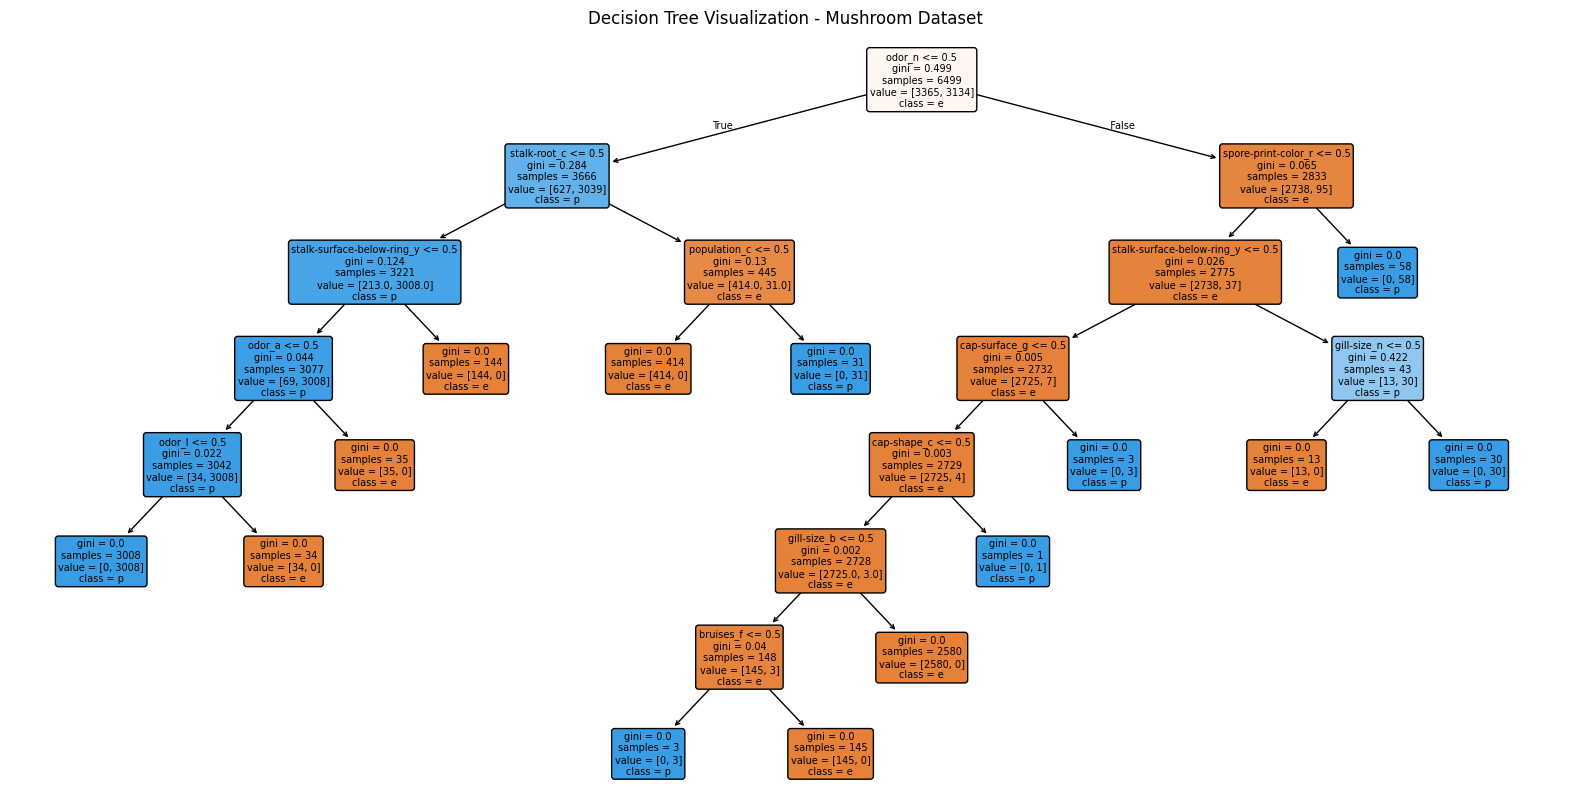

In [ ]:
# Decision Tree Visualization

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['e', 'p'],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Visualization - Mushroom Dataset")
plt.show()

In [ ]:
# Display Decision Tree Rules

rules = export_text(dt_model, feature_names=list(X.columns))

print("Decision Tree Rules:")
print(rules)

Decision Tree Rules:
|--- odor_n <= 0.50
|   |--- stalk-root_c <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- odor_a <= 0.50
|   |   |   |   |--- odor_l <= 0.50
|   |   |   |   |   |--- class: p
|   |   |   |   |--- odor_l >  0.50
|   |   |   |   |   |--- class: e
|   |   |   |--- odor_a >  0.50
|   |   |   |   |--- class: e
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- class: e
|   |--- stalk-root_c >  0.50
|   |   |--- population_c <= 0.50
|   |   |   |--- class: e
|   |   |--- population_c >  0.50
|   |   |   |--- class: p
|--- odor_n >  0.50
|   |--- spore-print-color_r <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- cap-surface_g <= 0.50
|   |   |   |   |--- cap-shape_c <= 0.50
|   |   |   |   |   |--- gill-size_b <= 0.50
|   |   |   |   |   |   |--- bruises_f <= 0.50
|   |   |   |   |   |   |   |--- class: p
|   |   |   |   |   |   |--- bruises_f >  0.50
|   |   |   |   |   |   |   |--- class: e
|   |   |   |  

In [ ]:
# Step 11: Feature Importance

importance = dt_model.feature_importances_

feature_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_df = feature_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Important Features:")
print(feature_df.head(10))

Top 10 Important Features:
                        Feature  Importance
27                       odor_n    0.623110
53                 stalk-root_c    0.179952
63   stalk-surface-below-ring_y    0.093620
100         spore-print-color_r    0.034084
22                       odor_a    0.020850
25                       odor_l    0.020719
105                population_c    0.017773
36                  gill-size_n    0.005589
7                 cap-surface_g    0.001841
20                    bruises_f    0.001811


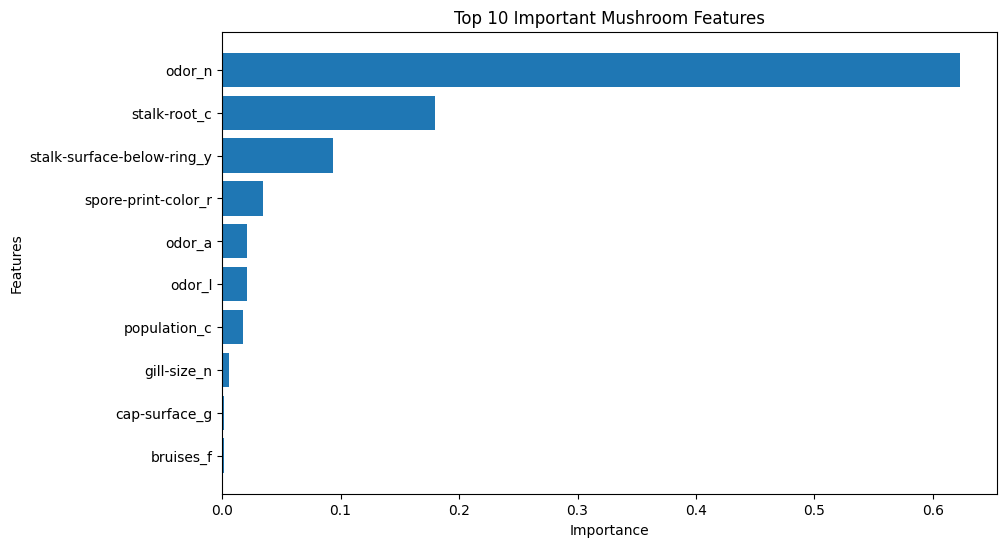

In [ ]:
# Step 12: Visualize Feature Importance

plt.figure(figsize=(10, 6))

plt.barh(
    feature_df.head(10)['Feature'],
    feature_df.head(10)['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Mushroom Features")

plt.gca().invert_yaxis()
plt.show()

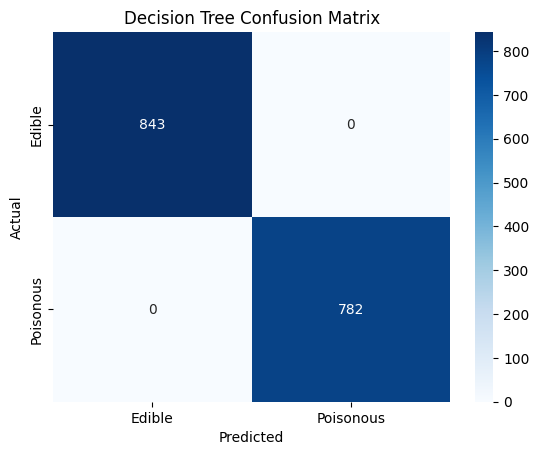

In [ ]:
# Step 13: Confusion Matrix

cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Edible', 'Poisonous'],
    yticklabels=['Edible', 'Poisonous']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [ ]:
# Step 14: Model Performance Comparison

results = pd.DataFrame({
    'Model': ['Decision Tree', 'Naive Bayes', 'KNN'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_knn)
    ],
    'Precision': [
        precision_score(y_test, y_pred_dt, pos_label='p'),
        precision_score(y_test, y_pred_nb, pos_label='p'),
        precision_score(y_test, y_pred_knn, pos_label='p')
    ],
    'Recall': [
        recall_score(y_test, y_pred_dt, pos_label='p'),
        recall_score(y_test, y_pred_nb, pos_label='p'),
        recall_score(y_test, y_pred_knn, pos_label='p')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_dt, pos_label='p'),
        f1_score(y_test, y_pred_nb, pos_label='p'),
        f1_score(y_test, y_pred_knn, pos_label='p')
    ]
})

print("Final Model Comparison:")
print(results.round(4))

Final Model Comparison:
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree      1.00     1.0000     1.0    1.0000
1    Naive Bayes      0.96     0.9233     1.0    0.9601
2            KNN      1.00     1.0000     1.0    1.0000


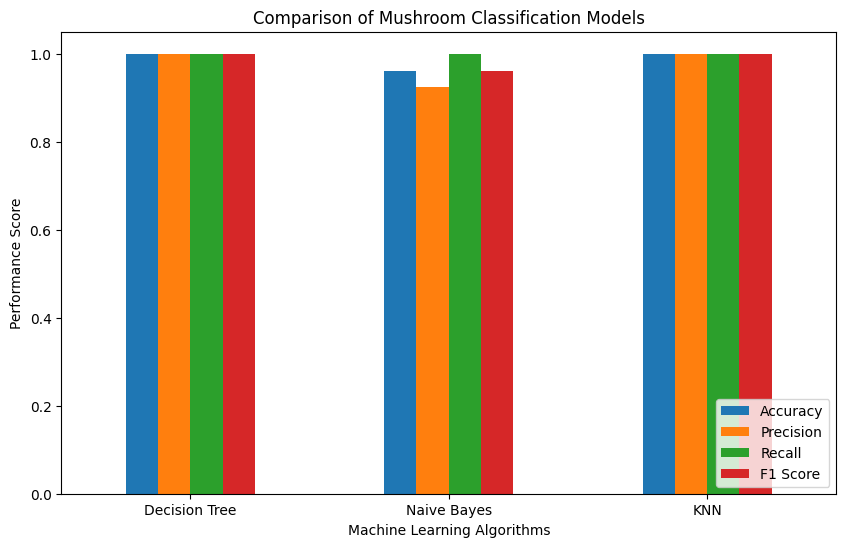

In [ ]:
# Step 15: Model Comparison Graph

results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Comparison of Mushroom Classification Models")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [ ]:
# Step 16: Actual vs Predicted Comparison

comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Decision Tree': y_pred_dt,
    'Naive Bayes': y_pred_nb,
    'KNN': y_pred_knn
})

print(comparison.head(20))

   Actual Decision Tree Naive Bayes KNN
0       e             e           e   e
1       p             p           p   p
2       p             p           p   p
3       e             e           e   e
4       p             p           p   p
5       p             p           p   p
6       p             p           p   p
7       p             p           p   p
8       e             e           e   e
9       e             e           e   e
10      e             e           p   e
11      p             p           p   p
12      e             e           e   e
13      e             e           e   e
14      e             e           p   e
15      e             e           e   e
16      e             e           e   e
17      p             p           p   p
18      e             e           e   e
19      e             e           e   e


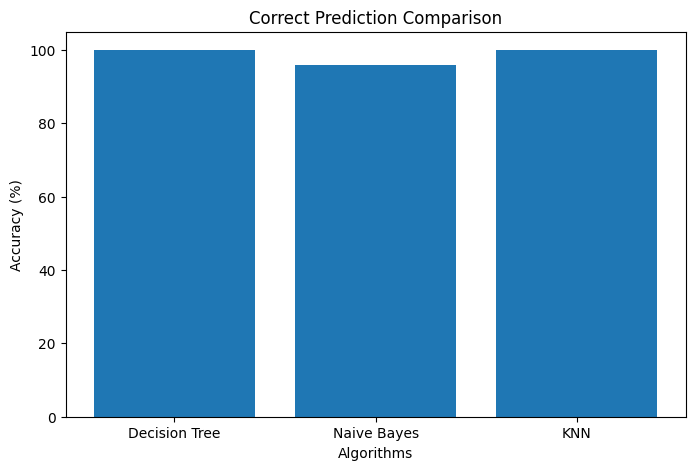

In [ ]:
# Step 17: Correct Prediction Comparison

correct = {
    'Decision Tree': accuracy_score(y_test, y_pred_dt) * 100,
    'Naive Bayes': accuracy_score(y_test, y_pred_nb) * 100,
    'KNN': accuracy_score(y_test, y_pred_knn) * 100
}

plt.figure(figsize=(8, 5))

plt.bar(correct.keys(), correct.values())

plt.title("Correct Prediction Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

plt.show()

## Final Results

In this project, three machine learning algorithms were implemented to classify mushrooms as edible or poisonous.

The performance of the models was evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The results obtained from the three algorithms were compared to identify the best-performing model.

The Decision Tree, Naive Bayes, and K-Nearest Neighbors algorithms demonstrated their ability to classify mushrooms based on their physical characteristics.

The final model selection is based on the evaluation results obtained during testing.

# **Conclusion**
The Mushroom Classification project uses machine learning algorithms to classify mushrooms as edible or poisonous based on their physical characteristics.

Three algorithms were implemented:
- Decision Tree Classifier
- Naive Bayes Classifier
- K-Nearest Neighbors (KNN)
Their performance was compared using accuracy, precision, recall, and F1-score. Confusion matrices and visualizations were also used to evaluate the models.

The project demonstrates how machine learning can be applied to mushroom classification.